<h1/>Example of inference to classify chest X-ray images as: "normal" or "pathological"</h1>

<h1/>Imports</h1>

In [2]:
# General libraries
import os
import pandas as pd
import numpy as np
from enum import Enum
from PIL import Image
import random
import ast
import skimage
import matplotlib.pyplot as plt
#%matplotlib notebook
%matplotlib inline
import logging

# AI framework
import torch
from torchvision import transforms
import torch.nn.functional as F
import torch.nn as nn
import torchvision.models as models

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'Device: {DEVICE}')

# Specific resources
from preprocess.preprocess import preprocess

Device: cuda


<h1/>1. Load model</h1>

<h2/>Option 1: Replicate GitHub Code</2>

In [3]:
# -------This cell can be deleted-----------
class Models(Enum):
    resnet18 = 'resnet18'
    def __str__(self):
        return self.value
# -------This cell can be deleted-----------

In [4]:
class Classifier(nn.Module):
    def __init__(self, model, classes):
        super(Classifier)

        if model == Models.resnet18:
            self.model = models.resnet18(pretrained=True)
            num_ftrs = self.model.fc.in_features
            self.model.fc = nn.Linear(num_ftrs, classes)
            
    def forward(self, image):
        output = self.model(image)
        return output

In [5]:
class Hook():
    def __init__(self):
        self.stored = []

    def hook_func(self, m, i, o):
        self.stored.append(o.data.cpu().numpy())

In [6]:
class ResnetCAM(nn.Module):
    def __init__(self, path):
        super(ResnetCAM, self).__init__()

        self.resnet = torch.load(path, map_location = torch.device(DEVICE))
        self.hook_output = Hook()
        self.resnet.model.layer4.register_forward_hook(self.hook_output.hook_func )

    def activations_hook(self):
        return self.hook_output.stored

    def forward(self, x):
        x = self.resnet(x)
        return x

    def weight_softmax(self):
        params = list(self.resnet.parameters())
        weight_softmax = np.squeeze(params[-2].data.numpy())
        return weight_softmax

    def get_activations_gradient(self):
        return self.gradients

    def get_activations(self, x):
        return self.features_conv(x)

In [19]:
# LOAD normal-resnet18
model_ResnetCAM = ResnetCAM(os.path.join(os.path.join('./Models/','normal-resnet18.pth')))
#print(len(dir(model)))

<h2/>Option 2: Simplify the code (Load the model without using ResnetCAM)</2>

In [8]:
class Classifier(nn.Module):
    def __init__(self, model, classes):
        super(Classifier)

        if model == Models.resnet18:
            self.model = models.resnet18(pretrained=True)
            num_ftrs = self.model.fc.in_features
            self.model.fc = nn.Linear(num_ftrs, classes)
            
    def forward(self, image):
        output = self.model(image)
        return output

In [9]:
# LOAD normal-resnet18
model = torch.load(os.path.join('./Models/','normal-resnet18.pth'), map_location = torch.device(DEVICE))

# Parameters
#print(len(dir(model)))

<h2/>Option 3: Option 2 + Simplify the model structure (Save the model without the "Classifier" class)</2>

<h3/>Save the model: Run this section just once</h3>

In [10]:
class Classifier(nn.Module):
    def __init__(self, model, classes):
        super(Classifier)

        if model == Models.resnet18:
            self.model = models.resnet18(pretrained=True)
            num_ftrs = self.model.fc.in_features
            self.model.fc = nn.Linear(num_ftrs, classes)
            
    def forward(self, image):
        output = self.model(image)
        return output

In [11]:
# LOAD normal-resnet18
model = torch.load(os.path.join('./Models/','normal-resnet18.pth'), map_location = torch.device(DEVICE))

# Extract the structure of the renet model
resnet18 = model.model

# SAVE normal-resnet18 (without the Classifier Class)
torch.save(resnet18, './Models/normal-resnet18-simplified.pth')
# print(len(dir(model)))

<h3/>Load the model</h3>

In [12]:
# LOAD normal-resnet18
model = torch.load(os.path.join('./Models/','normal-resnet18-simplified.pth'), map_location = torch.device(DEVICE))

<h1/>Load a random image and visualize the label</h1>

<h3/>Select an image randomly from the original PadChest Dataset</h3>

In [59]:
# Folder with the images
#images_folder= '../PadChest224/images'  # PadChest 224
images_folder = '../PadChest_original_zip0/images'# Original PadChest

# Select a random image from the folder
images_list = os.listdir(images_folder)
random_image_path= random.choice(images_list)
image_path = os.path.join(images_folder, random_image_path)
print ('Image selected:', random_image_path)

Image selected: 85069281774391405586820015499225826700_fqfhrm.png


<h3/>Obtain the labels for that image</h3>

In [60]:
# Load the csv file
csv_file = '../PadChest_original_zip0/PADCHEST_chest_x_ray_images_labels_160K_01.02.19.csv'
csv_table = pd.read_csv(csv_file, low_memory = False)

# Obtain the information just for the image of interest
csv_table = csv_table[csv_table["ImageID"].isin([random_image_path])]
labels = csv_table['Labels'].iloc[0]
print('Labels:', labels)

# Convert the string of labels into a list
label_list = ast.literal_eval(labels)

# Select the first label to check if it is "normal"
print ('First label:', label_list[0])
print ('View', csv_table['Projection'].iloc[0])

# Only PA or AP views. Error message:
image_view = csv_table['Projection'].iloc[0]
if image_view != 'PA' and image_view!= 'AP' and image_view != 'AP_horizontal':
    logging.error("Invalid view: Your image is not a frontal projection. Model performance may be affected")

Labels: ['vertebral degenerative changes', 'scoliosis']
First label: vertebral degenerative changes
View PA


<h1/>Preprocess the image: Replicate all the steps of the the original code</h1>

In [61]:
# Define the transforms
transform = transforms.Compose([
                            transforms.Resize((1024,1024)),
                            transforms.ToTensor()
                            ])

# Preprocess the image
image_process = preprocess(image_path, "MONOCHROME2")
image_process = image_process[...,::-1]

# Apply transforms to the preprocessed image
img_trans = transform(Image.fromarray(image_process)).unsqueeze(0).to(DEVICE)

YOLOv5  2023-3-28 torch 1.10.2 CUDA:0 (GeForce GTX 1650 Ti, 4096.0MB)

Fusing layers... 
Model Summary: 224 layers, 7078183 parameters, 0 gradients


image 1/1 C:\tmp\yolo\img.jpg: 640x640 1 lung_left, 1 lung_right, 1 clavicle_left, 1 clavicle_right, 1 humeral_head_left, 1 humeral_head_right, 1 heart, 1 trachea, Done. (0.016s)
Results saved to \tmp\yolo\exp
1 labels saved to \tmp\yolo\exp\labels
Done. (0.514s)


-------------Images size-------------------
Original image size: (3668, 3616)
Processed image size: (3502, 3383, 3)
Transformed image size: (1024, 1024)
-------------------------------------------


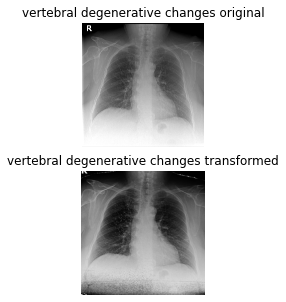

In [62]:
# Original image
print('-------------Images size-------------------')
original_image = skimage.io.imread(image_path)
print('Original image size:', original_image.shape)

# Processed image
print('Processed image size:', image_process.shape)

# Transformed image: Processed + resize
transformed_image = img_trans.cpu().squeeze()[0].numpy()
print('Transformed image size:', transformed_image.shape)
print('-------------------------------------------')

# Plot: Original image
figure = plt.figure(figsize=(5, 5))
figure.add_subplot(2, 1, 1)
plt.title(label_list[0] + ' original')
plt.axis("off")
plt.imshow(original_image.squeeze(), cmap = 'gray')

# Plot: Transformed image
figure.add_subplot(2, 1, 2)
plt.title(label_list[0] + ' transformed')
plt.axis("off")
plt.imshow(transformed_image, cmap = 'gray')

<h1/>Run the inference</h1>

In [63]:
output= model(img_trans)
h_x = F.softmax(output, dim=1).data.squeeze()
prob = h_x.cpu().numpy()

In [64]:
#Obtain the probabilities of each class
probs = (torch.nn.functional.softmax(output, dim=1)[0] * 100).tolist()

# determine the most probable class
class_labels = ["abnormal","normal"]
mostProbableClass = class_labels[probs.index(max(probs))]

print(f"The prediction is {mostProbableClass} with a probability of {max(probs)} %" )

The prediction is normal with a probability of 75.54380798339844 %
